In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [ ]:
#check if the dataset is in the current directory and find the project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

print("Current directory:", current_dir)
print("Project root:", project_root)
print("Dataset path:", dataset_path)
print("Dataset exists:", dataset_path.exists())

Current directory: /Users/janiththenura/University/AI-Group-Project-UW/notebooks
Project root: /Users/janiththenura/University/AI-Group-Project-UW
Dataset path: /Users/janiththenura/University/AI-Group-Project-UW/data/raw/manufacturing_6G_dataset.csv
Dataset exists: True


In [7]:
#reading the csv file from the dataset path
df = pd.read_csv(dataset_path)
if df.empty:
    print("Dataset is empty")
else:
    print("Dataset loaded successfully")

#display the first few rows of the dataset
print("Shape:", df.shape)



Dataset loaded successfully
Shape: (100000, 13)


In [ ]:
#display the first few rows of the dataset
df.head()

,Timestamp,Machine_ID,Operation_Mode,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%,Efficiency_Status
0,2024-01-01 00:00:00,39,Idle,74.137590,3.500595,8.612162,10.650542,0.207764,7.751261,477.657391,0.344650,14.965470,Low
1,2024-01-01 00:01:00,29,Active,84.264558,3.355928,2.268559,29.111810,2.228464,4.989172,398.174747,0.769848,7.678270,Low
2,2024-01-01 00:02:00,15,Active,44.280102,2.079766,6.144105,18.357292,1.639416,0.456816,108.074959,0.987086,8.198391,Low
3,2024-01-01 00:03:00,43,Active,40.568502,0.298238,4.067825,29.153629,1.161021,4.582974,329.579410,0.983390,2.740847,Medium
4,2024-01-01 00:04:00,8,Idle,75.063817,0.345810,6.225737,34.029191,4.796520,2.287716,159.113525,0.573117,12.100686,Low


In [ ]:
# display the information of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Timestamp                      100000 non-null  str    
 1   Machine_ID                     100000 non-null  int64  
 2   Operation_Mode                 100000 non-null  str    
 3   Temperature_C                  100000 non-null  float64
 4   Vibration_Hz                   100000 non-null  float64
 5   Power_Consumption_kW           100000 non-null  float64
 6   Network_Latency_ms             100000 non-null  float64
 7   Packet_Loss_%                  100000 non-null  float64
 8   Quality_Control_Defect_Rate_%  100000 non-null  float64
 9   Production_Speed_units_per_hr  100000 non-null  float64
 10  Predictive_Maintenance_Score   100000 non-null  float64
 11  Error_Rate_%                   100000 non-null  float64
 12  Efficiency_Status              100000 non-

In [12]:
#display the summary statistics of the dataset
df.describe()

,Machine_ID,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,25.499330,60.041458,2.549959,5.745929,25.555620,2.493418,5.008806,275.916324,0.499385,7.504100
std,14.389439,17.323238,1.414127,2.451271,14.120758,1.443273,2.883666,130.096892,0.288814,4.335896
min,1.000000,30.000138,0.100011,1.500183,1.000025,0.000026,0.000449,50.000375,0.000003,0.000112
25%,13.000000,45.031596,1.323214,3.627318,13.355118,1.245026,2.521591,162.873618,0.248166,3.750148
50%,25.000000,60.033597,2.549441,5.755460,25.536079,2.487667,5.003569,276.648922,0.499209,7.504145
75%,38.000000,74.967217,3.776459,7.860267,37.796372,3.741252,7.506127,388.812761,0.748810,11.273189
max,50.000000,89.998979,4.999974,9.999889,49.999917,4.999975,9.999900,499.996768,0.999978,14.999869


In [ ]:
# checking for the missing values in the dataset
df.isnull().sum()

Timestamp                        0
Machine_ID                       0
Operation_Mode                   0
Temperature_C                    0
Vibration_Hz                     0
Power_Consumption_kW             0
Network_Latency_ms               0
Packet_Loss_%                    0
Quality_Control_Defect_Rate_%    0
Production_Speed_units_per_hr    0
Predictive_Maintenance_Score     0
Error_Rate_%                     0
Efficiency_Status                0
dtype: int64

In [ ]:
# checking for the duplicate rows in the dataset
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [ ]:
# cheching the catrgotical values in the dataset
print(df["Operation_Mode"].value_counts())
print()
print(df["Efficiency_Status"].value_counts())

Operation_Mode
Active         70054
Idle           20057
Maintenance     9889
Name: count, dtype: int64

Efficiency_Status
Low       77825
Medium    19189
High       2986
Name: count, dtype: int64


In [17]:
class_percentages = (
    df["Efficiency_Status"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Efficiency Status Percentage Distribution:")
print(class_percentages)

Efficiency Status Percentage Distribution:
Efficiency_Status
Low       77.825
Medium    19.189
High       2.986
Name: proportion, dtype: float64


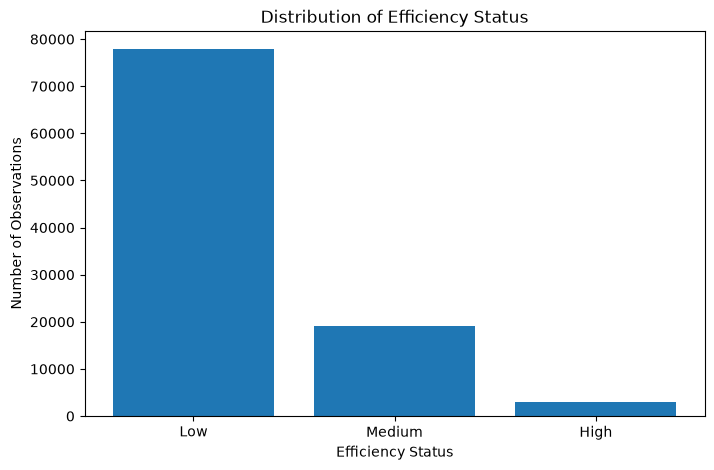

In [ ]:
# visualizing the distribution of the efficiency status, since from the previous cell we see that the dataset is imbalanced
class_counts = df["Efficiency_Status"].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Distribution of Efficiency Status")
plt.xlabel("Efficiency Status")
plt.ylabel("Number of Observations")

plt.show()

In [20]:
# Machine_ID has an int64 datatype, so Python sees it as a number.
# But conceptually it is not a numerical measurement.
# Numeric datatype ≠ Meaningful numerical feature
        
print("Number of unique machines:", df["Machine_ID"].nunique())
print("Minimum Machine ID:", df["Machine_ID"].min())
print("Maximum Machine ID:", df["Machine_ID"].max())

Number of unique machines: 50
Minimum Machine ID: 1
Maximum Machine ID: 50


In [22]:
# Convert and inspect the Timestamp column
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Timestamp data type:", df["Timestamp"].dtype)
print("Start time:", df["Timestamp"].min())
print("End time:", df["Timestamp"].max())

Timestamp data type: datetime64[us]
Start time: 2024-01-01 00:00:00
End time: 2024-03-10 10:39:00


In [24]:
# check the time interval between observations
time_intervals = (
    df["Timestamp"]
    .sort_values()
    .diff()
    .value_counts()
)

print(time_intervals.head())

Timestamp
0 days 00:01:00    99999
Name: count, dtype: int64


##### observations are recorded roughly every 1 minute.
Why is this useful?
This tells us whether the data is sampled at a regular interval.
That matters because if observations are evenly spaced in time, then later we can reason about:
1. time based patterns
2. possible temporal dependence
3. whether random train test splitting is appropriate
4. whether we may want a time based split as an additional experiment

In [25]:
# correlation between features
numeric_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

corr_matrix = df[numeric_features].corr()

corr_matrix

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Temperature_C,1.000000,0.000610,0.004584,-0.002467,0.002861,-0.002238,0.001451,-0.002188,-0.001806
Vibration_Hz,0.000610,1.000000,0.005340,0.007546,0.000396,0.000357,-0.001335,0.003957,0.004579
Power_Consumption_kW,0.004584,0.005340,1.000000,-0.003245,-0.001198,-0.000918,0.001970,0.001627,0.000889
Network_Latency_ms,-0.002467,0.007546,-0.003245,1.000000,-0.006886,-0.004356,-0.001050,-0.002901,0.000098
Packet_Loss_%,0.002861,0.000396,-0.001198,-0.006886,1.000000,-0.004897,-0.007119,0.000756,-0.002406
Quality_Control_Defect_Rate_%,-0.002238,0.000357,-0.000918,-0.004356,-0.004897,1.000000,-0.004937,-0.000168,-0.001487
Production_Speed_units_per_hr,0.001451,-0.001335,0.001970,-0.001050,-0.007119,-0.004937,1.000000,0.003511,0.006070
Predictive_Maintenance_Score,-0.002188,0.003957,0.001627,-0.002901,0.000756,-0.000168,0.003511,1.000000,0.004525
Error_Rate_%,-0.001806,0.004579,0.000889,0.000098,-0.002406,-0.001487,0.006070,0.004525,1.000000


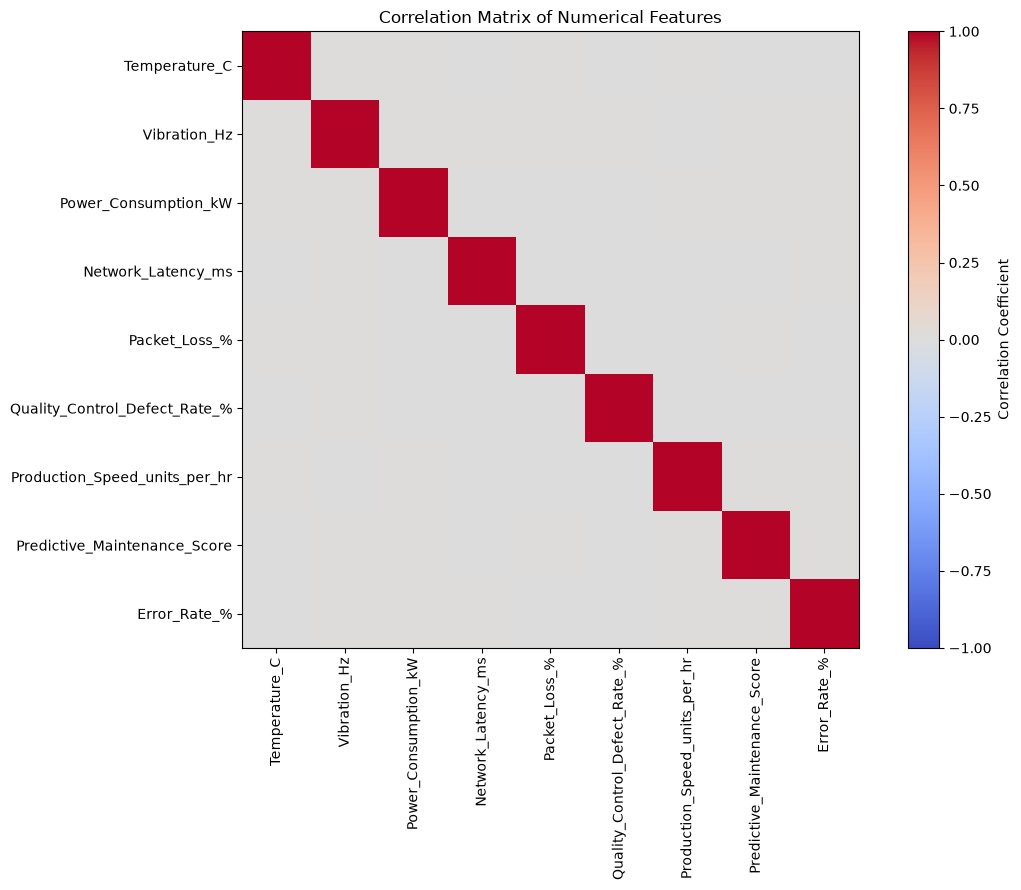

In [27]:
# Visualize the correlation matrix
plt.figure(figsize=(12, 9))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

In [ ]:
# Compare mean numerical measurements across efficiency classes
class_means = (
    df.groupby("Efficiency_Status")[numeric_features]
    .mean()
    .round(3)
)

class_means

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Efficiency_Status,,,,,,,,,
High,60.232,2.548,5.718,25.334,2.528,4.930,450.791,0.495,1.007
Low,60.006,2.550,5.743,25.562,2.494,5.017,254.854,0.500,8.930
Medium,60.154,2.552,5.762,25.566,2.487,4.989,334.125,0.498,2.733
